In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.home() / "projects" / "loan-default-risk"
df = pd.read_parquet(root / "data" / "processed" / "features.parquet")

not_features = ["split", "issue_year", "target"]
train, valid, test = (df[df["split"] == s] for s in ["train", "valid", "test"])
X_train, y_train = train.drop(columns=not_features), train["target"]
X_valid, y_valid = valid.drop(columns=not_features), valid["target"]
X_test, y_test = test.drop(columns=not_features), test["target"]
print(X_train.shape, X_valid.shape, X_test.shape)

(826604, 64) (293095, 64) (169300, 64)


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print(len(num_cols), "numeric,", len(cat_cols), "categorical")

pre = ColumnTransformer(
    [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
     ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat_cols)],
    sparse_threshold=0)

57 numeric, 7 categorical


In [3]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=300))])
model.fit(X_train, y_train)
print("done")

done


In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score

p_valid = model.predict_proba(X_valid)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

res = {
    "model": "Logistic regression (baseline)",
    "valid_roc_auc": roc_auc_score(y_valid, p_valid),
    "valid_pr_auc": average_precision_score(y_valid, p_valid),
    "test_roc_auc": roc_auc_score(y_test, p_test),
    "test_pr_auc": average_precision_score(y_test, p_test),
}
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in res.items()})
print("PR AUC of a random model (default rate):", round(y_valid.mean(), 4), "valid,", round(y_test.mean(), 4), "test")

{'model': 'Logistic regression (baseline)', 'valid_roc_auc': 0.7053, 'valid_pr_auc': 0.4156, 'test_roc_auc': 0.6938, 'test_pr_auc': 0.3875}
PR AUC of a random model (default rate): 0.2328 valid, 0.2312 test


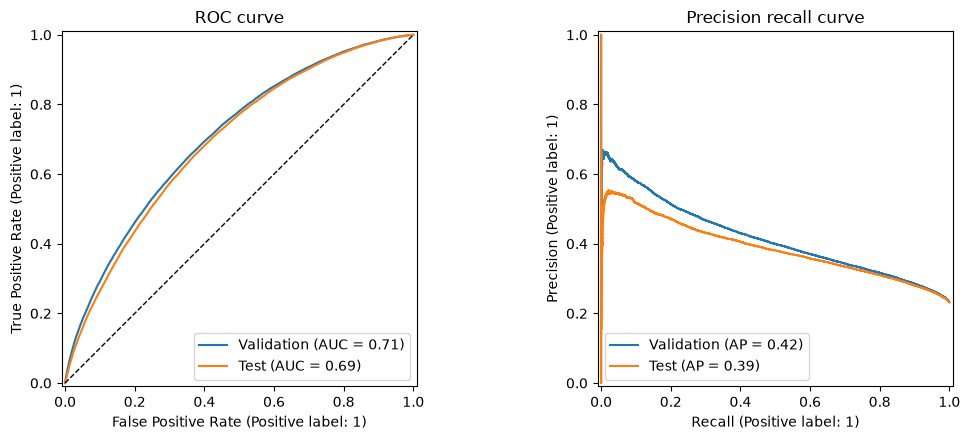

In [5]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_valid, p_valid, ax=ax[0], name="Validation")
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[0], name="Test")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_valid, p_valid, ax=ax[1], name="Validation")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[1], name="Test")
ax[1].set_title("Precision recall curve")
plt.tight_layout()
(root / "reports" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(root / "reports" / "figures" / "baseline_curves.png", dpi=150)
plt.show()

In [6]:
pd.DataFrame([res]).round(4).to_csv(root / "reports" / "results.csv", index=False)
pd.read_csv(root / "reports" / "results.csv")

,model,valid_roc_auc,valid_pr_auc,test_roc_auc,test_pr_auc
0,Logistic regression (baseline),0.7053,0.4156,0.6938,0.3875
